In [ ]:
import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

columns = ["Variance", "Skewness", "Curtosis", "Entropy", "Class"]

df = pd.read_csv(url, header=None, names=columns)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head(10)

Dataset loaded successfully!
Shape: (1372, 5)


,Variance,Skewness,Curtosis,Entropy,Class
0,3.62160,8.6661,-2.80730,-0.44699,0
1,4.54590,8.1674,-2.45860,-1.46210,0
2,3.86600,-2.6383,1.92420,0.10645,0
3,3.45660,9.5228,-4.01120,-3.59440,0
4,0.32924,-4.4552,4.57180,-0.98880,0
5,4.36840,9.6718,-3.96060,-3.16250,0
6,3.59120,3.0129,0.72888,0.56421,0
7,2.09220,-6.8100,8.46360,-0.60216,0
8,3.20320,5.7588,-0.75345,-0.61251,0
9,1.53560,9.1772,-2.27180,-0.73535,0


In [ ]:
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])
df.dtypes
df.isnull().sum()
print("Number of duplicate records:", df.duplicated().sum())
df.describe()
print("Class counts:")
print(df["Class"].value_counts())

print("\nClass percentages:")
print(df["Class"].value_counts(normalize=True) * 100)


Number of records: 1372
Number of columns: 5
Number of duplicate records: 24
Class counts:
Class
0    762
1    610
Name: count, dtype: int64

Class percentages:
Class
0    55.539359
1    44.460641
Name: proportion, dtype: float64


### Dataset Exploration Observations

The Banknote Authentication dataset contains 1,372 records and 5 columns. It has four input features: Variance, Skewness, Curtosis, and Entropy. The target variable is Class.

The dataset was checked for missing values and duplicate records. Descriptive statistics were used to understand the numerical ranges and distributions of the features.

The class distribution was examined to understand the representation of Class 0 and Class 1. The four features have different numerical ranges, so feature scaling is useful for Logistic Regression.


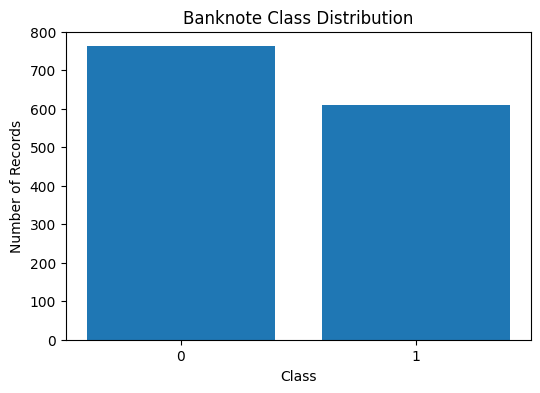

In [ ]:
import matplotlib.pyplot as plt

class_counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.xlabel("Class")
plt.ylabel("Number of Records")
plt.title("Banknote Class Distribution")
plt.show()

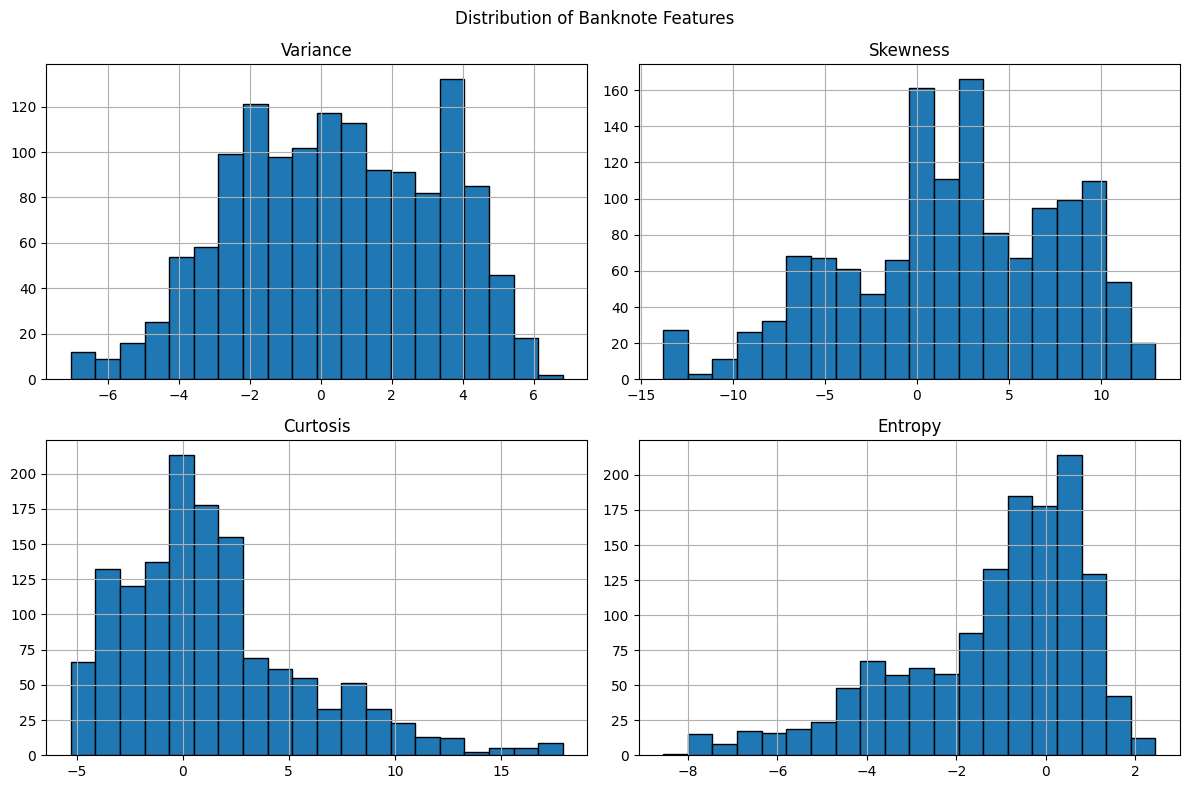

In [ ]:
features = ["Variance", "Skewness", "Curtosis", "Entropy"]

df[features].hist(figsize=(12, 8), bins=20, edgecolor="black")
plt.suptitle("Distribution of Banknote Features")
plt.tight_layout()
plt.show()

**Visualization Observations**

1. The bar chart shows the distribution of Class 0 and Class 1 records.
2. The histograms show the distributions and different numerical ranges of the four input features.
3. The scatter plots show how the two classes are distributed across different feature pairs. The plots help identify patterns and areas where the classes overlap.


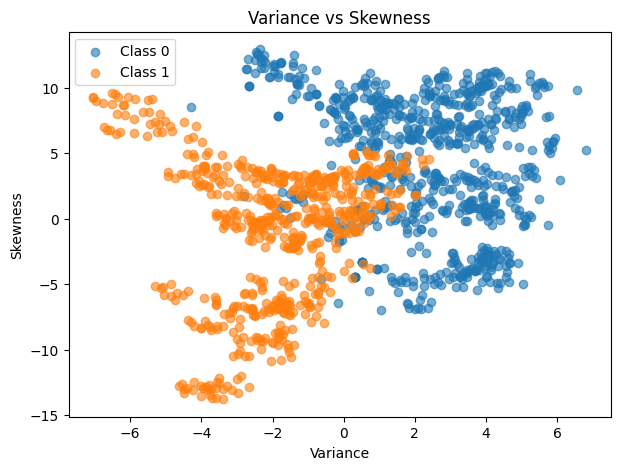

In [ ]:
plt.figure(figsize=(7, 5))

for class_label in sorted(df["Class"].unique()):
    subset = df[df["Class"] == class_label]
    plt.scatter(
        subset["Variance"],
        subset["Skewness"],
        label=f"Class {class_label}",
        alpha=0.6
    )

plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.title("Variance vs Skewness")
plt.legend()
plt.show()

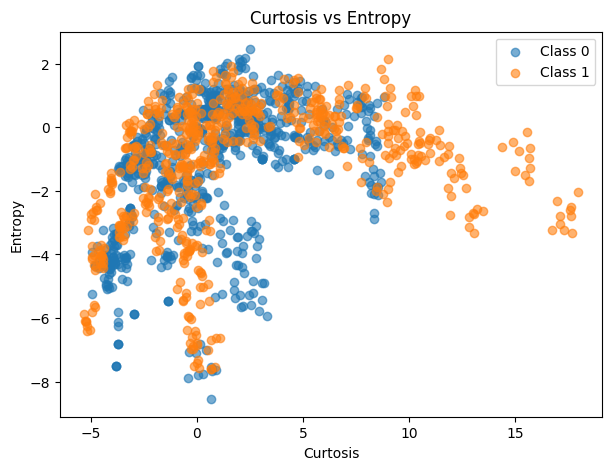

In [ ]:
plt.figure(figsize=(7, 5))

for class_label in sorted(df["Class"].unique()):
    subset = df[df["Class"] == class_label]
    plt.scatter(
        subset["Curtosis"],
        subset["Entropy"],
        label=f"Class {class_label}",
        alpha=0.6
    )

plt.xlabel("Curtosis")
plt.ylabel("Entropy")
plt.title("Curtosis vs Entropy")
plt.legend()
plt.show()

In [ ]:
# Separate input features (X) and target variable (y)
X = df[["Variance", "Skewness", "Curtosis", "Entropy"]]
y = df["Class"]

print("Number of input features:", X.shape[1])
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Number of input features: 4
Shape of X: (1372, 4)
Shape of y: (1372,)
Training records: 1097
Testing records: 275
Scaled training shape: (1097, 4)
Scaled testing shape: (275, 4)


In [ ]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train_scaled, y_train)

print("Model training completed successfully!")
y_pred = model.predict(X_test_scaled)

print("Actual labels:")
print(y_test.head(15).values)

print("\nPredicted labels:")
print(y_pred[:15])
y_prob = model.predict_proba(X_test_scaled)

print("Class order:", model.classes_)
print("\nFirst 10 probability predictions:")
print(y_prob[:10])
results = pd.DataFrame({
    "Actual Class": y_test.values,
    "Predicted Class": y_pred,
    "Probability Class 0": y_prob[:, 0],
    "Probability Class 1": y_prob[:, 1]
})

results.head(15)

Model training completed successfully!
Actual labels:
[0 1 0 1 1 1 0 0 0 1 0 1 0 0 0]

Predicted labels:
[0 1 0 1 1 1 0 0 0 1 0 1 0 0 0]
Class order: [0 1]

First 10 probability predictions:
[[9.99576433e-01 4.23567092e-04]
 [3.35717098e-02 9.66428290e-01]
 [7.55630532e-01 2.44369468e-01]
 [3.55676247e-02 9.64432375e-01]
 [6.95876485e-03 9.93041235e-01]
 [2.59980576e-01 7.40019424e-01]
 [9.99273658e-01 7.26341960e-04]
 [9.99798565e-01 2.01434923e-04]
 [9.96741365e-01 3.25863451e-03]
 [7.79046808e-02 9.22095319e-01]]


,Actual Class,Predicted Class,Probability Class 0,Probability Class 1
0,0,0,0.999576,0.000424
1,1,1,0.033572,0.966428
2,0,0,0.755631,0.244369
3,1,1,0.035568,0.964432
4,1,1,0.006959,0.993041
5,1,1,0.259981,0.740019
6,0,0,0.999274,0.000726
7,0,0,0.999799,0.000201
8,0,0,0.996741,0.003259
9,1,1,0.077905,0.922095


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)
print("Precision (Class 1):", precision)
print("Recall (Class 1):", recall)
print("F1-score (Class 1):", f1)

Accuracy: 0.9709090909090909
Accuracy (%): 97.0909090909091
Precision (Class 1): 0.9384615384615385
Recall (Class 1): 1.0
F1-score (Class 1): 0.9682539682539683


In [ ]:
print(classification_report(y_test, y_pred))
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)


              precision    recall  f1-score   support

           0       1.00      0.95      0.97       153
           1       0.94      1.00      0.97       122

    accuracy                           0.97       275
   macro avg       0.97      0.97      0.97       275
weighted avg       0.97      0.97      0.97       275

Confusion Matrix:
[[145   8]
 [  0 122]]


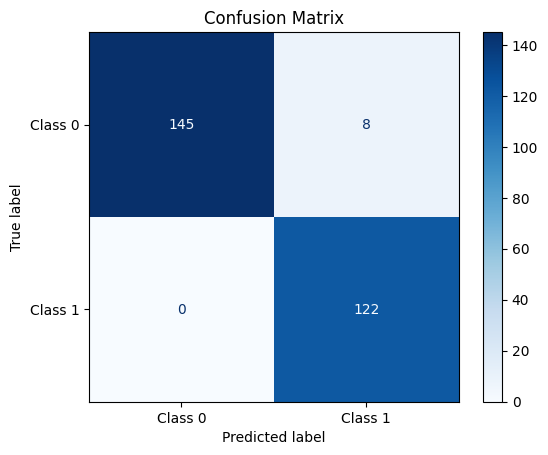

In [ ]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

### Model Evaluation Observations

The Logistic Regression model was evaluated using accuracy, precision, recall, and F1-score on the test dataset.

The confusion matrix shows the correct and incorrect predictions for both classes. False positives and false negatives represent different types of classification errors.

Using multiple evaluation metrics provides a more complete understanding of the model's performance than accuracy alone.


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

thresholds = [0.30, 0.50, 0.70]
threshold_results = []

for threshold in thresholds:
    # Predict Class 1 when its probability is >= threshold
    y_threshold_pred = (y_prob[:, 1] >= threshold).astype(int)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_threshold_pred)
    precision = precision_score(y_test, y_threshold_pred, pos_label=1, zero_division=0)
    recall = recall_score(y_test, y_threshold_pred, pos_label=1, zero_division=0)
    f1 = f1_score(y_test, y_threshold_pred, pos_label=1, zero_division=0)

    # Confusion matrix
    cm_threshold = confusion_matrix(y_test, y_threshold_pred, labels=[0, 1])

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "TN": cm_threshold[0, 0],
        "FP": cm_threshold[0, 1],
        "FN": cm_threshold[1, 0],
        "TP": cm_threshold[1, 1]
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(4)

,Threshold,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
0,0.3,0.9709,0.9385,1.0,0.9683,145,8,0,122
1,0.5,0.9709,0.9385,1.0,0.9683,145,8,0,122
2,0.7,0.9964,0.9919,1.0,0.9959,152,1,0,122


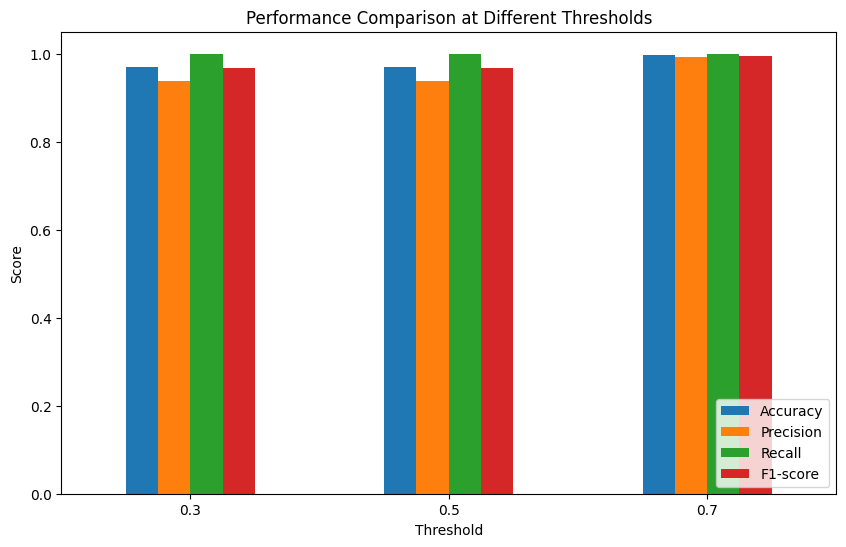

In [ ]:
threshold_df.set_index("Threshold")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Comparison at Different Thresholds")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

### Threshold Investigation Observations

The model was evaluated using classification thresholds of 0.30, 0.50, and 0.70.

A lower threshold generally increases the number of Class 1 predictions, while a higher threshold generally decreases them. Changing the threshold affects precision, recall, and the number of false positives and false negatives.

The appropriate threshold depends on the relative importance of different classification errors.